# Mach-Zehnder Interferometer on a Chip

A **directional coupler** is the beam splitter of integrated photonics: two waveguides run close together, and light leaks from one into the other. A coupler that sends half of the power into each output is the on-chip version of a 50:50 beam splitter. Two such couplers joined by two waveguide arms form a **Mach-Zehnder interferometer (MZI)**. MZIs with tunable arms are the unit cell of programmable photonic circuits, including photonic quantum processors [3].

In this challenge you first optimize a directional coupler towards a 50:50 split at 1550 nm. Then you use two copies of it to build an MZI, and choose the arm length difference so that all light leaves through one output port. The quality of the MZI is measured by its **extinction ratio**, and the extinction ratio is limited by how close the coupler is to 50:50.

This notebook gives you a working design. It shows how to:

- compute the guided mode of a silicon waveguide,
- estimate the coupling length of a directional coupler from the modes of the coupled waveguides,
- simulate the coupler with the finite-difference time-domain (FDTD) method,
- assemble and simulate the MZI as a circuit,
- score the design against the challenge constraints.

You change four parameters: the waveguide width, the coupler gap, the coupling length and the arm length difference $\Delta L$.

**References**

1. Chrostowski, L., and Hochberg, M. *Silicon Photonics Design: From Devices to Systems*. Cambridge University Press, 2015, doi: [10.1017/CBO9781316084168](https://doi.org/10.1017/CBO9781316084168).
2. Yariv, A. "Coupled-mode theory for guided-wave optics." *IEEE Journal of Quantum Electronics* 1973 9 (9), 919-933, doi: [10.1109/JQE.1973.1077767](https://doi.org/10.1109/JQE.1973.1077767).
3. Carolan, J., *et al*. "Universal linear optics." *Science* 2015 349 (6249), 711-716, doi: [10.1126/science.aab3642](https://doi.org/10.1126/science.aab3642).

## Physics primer

**Waveguide modes.** A silicon strip waveguide (refractive index about 3.48) surrounded by silica (about 1.44) guides light by total internal reflection. Each guided mode travels with an **effective index** $n_{eff}$: its phase advances by $2\pi n_{eff} L / \lambda$ over a length $L$ at the vacuum wavelength $\lambda$.

**Directional coupler.** When two identical waveguides are placed a small gap apart, their modes overlap and combine into two **supermodes** of the pair: an even one, with the field in phase in both guides, and an odd one, with opposite signs [2]. The two supermodes travel with slightly different effective indices, $n_{even}$ and $n_{odd}$. Light launched into one waveguide excites both supermodes equally, and as they drift out of phase the power moves into the other waveguide. After a length $L$ the fraction of power in the other waveguide (the **cross port**) is

$$P_{cross} = \sin^2\left(\frac{\pi\,\Delta n\,L}{\lambda}\right), \qquad \Delta n = n_{even} - n_{odd}.$$

A 50:50 split needs $\pi \Delta n L / \lambda = \pi/4$, so the required straight coupling length is

$$L_{50} = \frac{\lambda}{4\,\Delta n}.$$

The S-bends that bring the waveguides together and apart also couple some light, because the gap there is still small. The real straight section is therefore shorter than $L_{50}$.

**Design levers.** The evanescent field decays exponentially outside the core, so $\Delta n$ falls roughly exponentially as the gap grows. A narrower waveguide confines the mode less, which spreads the field further into the gap and increases $\Delta n$. Because $\Delta n$ and $\lambda$ both change with wavelength, the split also drifts across the band, which is what the stretch goal measures.

**Mach-Zehnder interferometer.** The first coupler splits the input between two arms. The arms differ in length by $\Delta L$, which adds a phase difference

$$\Delta\varphi = \frac{2\pi\,n_{eff}\,\Delta L}{\lambda}.$$

The second coupler recombines the two beams. With ideal 50:50 couplers the power in the bright output is

$$P_{out} = \cos^2\left(\frac{\Delta\varphi}{2}\right),$$

so all light exits one port when $\Delta\varphi$ is a whole multiple of $2\pi$. With $\Delta L = 0$ that port is the cross port of the MZI.

**Extinction ratio.** If the couplers send a fraction $k$ to the cross port instead of exactly one half, the two paths no longer cancel perfectly in the dark port. For $\Delta\varphi = 2\pi m$ the dark port receives $(1 - 2k)^2$ of the power, and the **extinction ratio**, the ratio of bright to dark output power, is

$$ER = 10 \log_{10}\frac{4k(1-k)}{(1 - 2k)^2}\ \text{dB}.$$

For example, $k = 0.49$ gives 34 dB, and $k = 0.495$ gives 40 dB, the cap of the score.

## Imports

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import photonforge as pf
import tidy3d as td
from photonforge.live_viewer import LiveViewer

# Start the interactive layout viewer
viewer = LiveViewer()

# We raise the Tidy3D logging level to reduce output noise from the
# simulations below. Warnings can flag real problems, so only suppress them
# once you have confirmed they are not relevant to your case.
td.config.logging.level = "ERROR"

C:\Users\grayd\anaconda3\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (1.26.16) or chardet (7.7.0)/charset_normalizer (2.0.4) doesn't match a supported version!
  warnings.warn(


LiveViewer started at http://127.0.0.1:54572. Call its 'stop()' method to free the port.


## Design parameters

These four values are the design. Keep each one inside its range. The starting values give a working coupler and MZI, but the coupler is far from 50:50, so the starting score is zero.

In [6]:
# Width of the silicon waveguides, allowed range 0.40 to 0.55 (μm)
width = 0.5

# Gap between the two waveguides in the coupler, allowed range 0.10 to 0.40 (μm)
gap = 2.197e-01

# Length of the straight coupling section, allowed range 0 to 30 (μm)
coupling_length = 1.834e+01 

# Arm length difference of the MZI, allowed range 0 to 100 (μm)
delta_length = 10.0

The rest of the layout is fixed. The S-bends of the coupler are 10 µm long and move each waveguide 2 µm sideways. The two couplers of the MZI sit 150 µm apart, and the MZI arms use a 10 µm bend radius. The simulations cover the telecom C band, 1530 to 1565 nm, in 1 nm steps.

In [8]:
s_bend_length = 10.0  # Length of each coupler S-bend (μm)
s_bend_offset = 2.0  # Lateral offset of each coupler S-bend (μm)
arm_length = 150.0  # Distance between the two couplers of the MZI (μm)
arm_radius = 10.0  # Bend radius of the MZI arms (μm)

# Wavelengths of the simulations (μm) and the corresponding frequencies (Hz)
wavelengths = np.linspace(1.530, 1.565, 36)
frequencies = pf.C_0 / wavelengths

# Index of the 1550 nm design wavelength
i_1550 = np.argmin(np.abs(wavelengths - 1.550))

## Technology and waveguide mode

PhotonForge's built-in [basic technology](https://docs.flexcompute.com/projects/photonforge/en/latest/_autosummary/photonforge.basic_technology.html) is a silicon-on-insulator platform: a 220 nm silicon layer on a 2 µm buried oxide, covered by silica. Its `"Strip"` port specification describes a strip waveguide, and the `strip_width` argument sets the waveguide width used everywhere below.

In [10]:
# Silicon-on-insulator technology with the chosen waveguide width
technology = pf.basic_technology(strip_width=width)
pf.config.default_technology = technology

# Port specification of the strip waveguide
strip = technology.ports["Strip"]
strip

PortSpec(description="Strip waveguide", width=2.25, limits=(-1, 1.22), num_modes=1, added_solver_modes=0, polarization="", target_neff=0, default_radius=0, path_profiles=[(0.5, 0, (2, 0)), (2.5, 0, (1, 0))])

The next cell solves for the fundamental transverse-electric (TE) mode of the strip waveguide across the band. The effective index sets the phase of the MZI arms. The group index $n_g$ sets the free spectral range of the MZI, the wavelength spacing between its transmission peaks, $\lambda^2 / (n_g \Delta L)$.

Starting…

14:51:35 Eastern Standard Time Loading simulation from local cache. View cached 
                               task using web UI at                             
                               ]8;id=941837;https://tidy3d.simulation.cloud/workbench?taskId=mo-b493cb9d-d2cc-4d87-b255-d0f4065b9ec7\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=767706;https://tidy3d.simulation.cloud/workbench?taskId=mo-b493cb9d-d2cc-4d87-b255-d0f4065b9ec7\taskId]8;;\
                               ]8;id=941837;https://tidy3d.simulation.cloud/workbench?taskId=mo-b493cb9d-d2cc-4d87-b255-d0f4065b9ec7\=]8;;\]8;id=881557;https://tidy3d.simulation.cloud/workbench?taskId=mo-b493cb9d-d2cc-4d87-b255-d0f4065b9ec7\mo]8;;\]8;id=941837;https://tidy3d.simulation.cloud/workbench?taskId=mo-b493cb9d-d2cc-4d87-b255-d0f4065b9ec7\-b493cb9d-d2cc-4d87-b255-d0f4065b9ec7']8;;\.

Progress: 100% 
Effective index at 1550 nm: 2.4401
Group index at 1550 nm: 4.1811


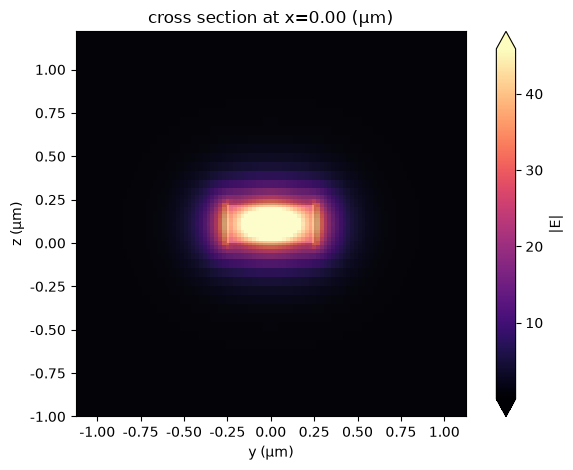

In [12]:
# Solve for the strip waveguide mode across the band
strip_modes = pf.port_modes("Strip", frequencies, group_index=True)

# Effective and group indices at 1550 nm
n_eff = strip_modes.data.n_eff.isel(mode_index=0).values[i_1550]
n_group = strip_modes.data.n_group.isel(mode_index=0).values[i_1550]
print(f"Effective index at 1550 nm: {n_eff:.4f}")
print(f"Group index at 1550 nm: {n_group:.4f}")

# Field magnitude of the mode at 1550 nm
_ = strip_modes.plot_field("E", "abs", mode_index=0, f=frequencies[i_1550])

## Coupling length estimate

The supermodes of the coupler come from a mode solve of a cross-section with both waveguides, a distance `width + gap` apart. This port specification is built only for the estimate, with two modes and the starting guess of the solver set to the silicon index. The estimate costs one mode solve, so it is a cheap way to explore the gap and width before you spend an FDTD run.

In [14]:
# Distance between the two waveguide centres in the coupler (μm)
coupling_distance = width + gap

# Cross-section with both waveguides and the silica cladding around them
coupled_strips = pf.PortSpec(
    description="Coupled strips",
    width=strip.width + coupling_distance,
    limits=strip.limits,
    num_modes=2,
    target_neff=3.5,
    path_profiles=[
        (width, coupling_distance / 2, "WG_CORE"),
        (width, -coupling_distance / 2, "WG_CORE"),
        (strip.path_profiles[1][0] + coupling_distance, 0, "WG_CLAD"),
    ],
)

# Solve for the even and odd supermodes at 1550 nm
supermodes = pf.port_modes(coupled_strips, [frequencies[i_1550]])
n_even, n_odd = supermodes.data.n_eff.values.ravel()

# Straight coupling length for a 50:50 split, without the S-bends (μm)
l_50 = 1.550 / (4 * (n_even - n_odd))
print(f"Supermode indices: {n_even:.4f} (even), {n_odd:.4f} (odd)")
print(f"Estimated 50:50 coupling length without the S-bends: {l_50:.1f} μm")

Uploading task 'Mode-ModeSolver…'
Starting task 'Mode-ModeSolver': https://tidy3d.simulation.cloud/workbench?taskId=mo-794820fc-c6cb-4335-9654-5a833066529a
Progress: 100% 
Supermode indices: 2.4486 (even), 2.4309 (odd)
Estimated 50:50 coupling length without the S-bends: 21.8 μm


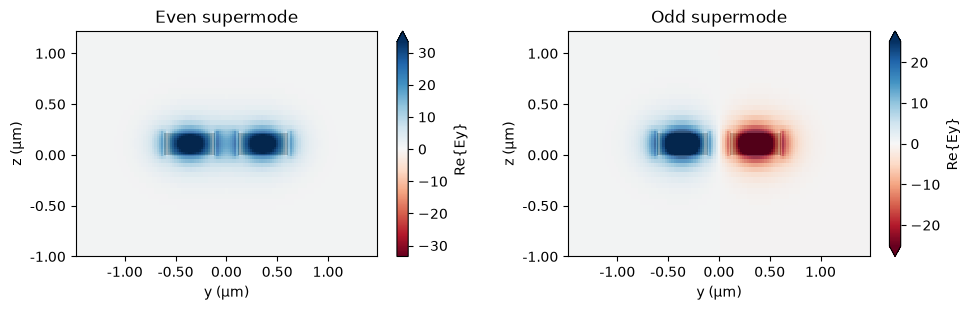

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3), tight_layout=True)

# Lateral field component of the even and odd supermodes
for m, name in enumerate(("Even", "Odd")):
    supermodes.plot_field("Ey", "real", mode_index=m, f=frequencies[i_1550], ax=ax[m])
    ax[m].set_title(f"{name} supermode")
plt.show()

## Directional coupler

The coupler is PhotonForge's [s_bend_coupler](https://docs.flexcompute.com/projects/photonforge/en/latest/_autosummary/photonforge.parametric.s_bend_coupler.html): two S-bends bring the waveguides to the gap, a straight section couples them, and two more S-bends separate them again. Its ports are:

- `P0`, bottom left, the input,
- `P1`, top left,
- `P2`, bottom right, the **through** port,
- `P3`, top right, the **cross** port.

The coupler is simulated with a [Tidy3DModel](https://docs.flexcompute.com/projects/photonforge/en/latest/_autosummary/photonforge.Tidy3DModel.html), which runs 3D FDTD. The coupler is mirror symmetric left to right and top to bottom, so every column of its scattering matrix follows from the single run with light entering `P0`. The `port_symmetries` argument lists these port swaps. The mesh uses 12 cells per wavelength (`grid_spec=12`), which keeps one run to about a minute.

Each S-bend is made of two circular arcs. For an S-bend of length $L_s$ and offset $H$, their radius is

$$R = \frac{L_s^2 + H^2}{4H}.$$

In [17]:
@pf.parametric_component
def directional_coupler(
    *,
    gap: float = 0.2,
    coupling_length: float = 5.0,
    s_bend_length: float = 10.0,
    s_bend_offset: float = 2.0,
):
    # Waveguide width taken from the strip port specification (μm)
    core_width = pf.config.default_technology.ports["Strip"].path_profiles[0][0]

    # Port swaps under the left-right, top-bottom and combined mirror symmetries
    port_symmetries = [
        ("P1", "P0", "P3", "P2"),
        ("P2", "P3", "P0", "P1"),
        ("P3", "P2", "P1", "P0"),
    ]

    # S-bend coupler simulated with FDTD
    return pf.parametric.s_bend_coupler(
        port_spec="Strip",
        coupling_distance=core_width + gap,
        s_bend_length=s_bend_length,
        s_bend_offset=s_bend_offset,
        coupling_length=coupling_length,
        model=pf.Tidy3DModel(port_symmetries=port_symmetries, grid_spec=12),
    )

coupler = directional_coupler(
    gap=gap,
    coupling_length=coupling_length,
    s_bend_length=s_bend_length,
    s_bend_offset=s_bend_offset,
)
viewer(coupler)


In [18]:
# Radius of the circular arcs in the coupler S-bends (μm)
s_bend_radius = (s_bend_length**2 + s_bend_offset**2) / (4 * s_bend_offset)
print(f"S-bend radius: {s_bend_radius:.1f} μm")

S-bend radius: 13.0 μm


The next cell builds the FDTD simulation without running it, plots it from the top and from the side, and asks the server for the cost of the run. Check the cost against your team's budget before you run.

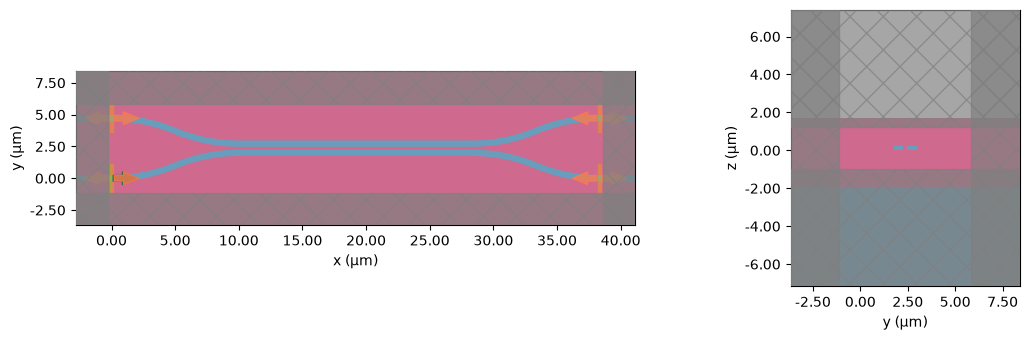

Uploading task 'P0@0…'
Estimated cost for task 'P0@0: 2.607457533439253'


In [20]:
# FDTD simulation with light entering P0
simulation = coupler.active_model.get_simulations(coupler, frequencies)["P0@0"]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), tight_layout=True)

# Top view through the middle of the silicon layer
simulation.plot(z=0.11, ax=ax[0])

# Side view through the middle of the coupling section
simulation.plot(x=simulation.center[0], ax=ax[1])
for a in ax:
    a.set_title("")
plt.show()

# Maximum cost of the run in FlexCredits
cost = coupler.active_model.estimate_cost(coupler, frequencies)

The next cell submits the FDTD run and waits for it. PhotonForge caches the result, so running the cell again with the same design costs nothing.

In [22]:
# Scattering matrix of the coupler from one FDTD run
s_coupler = coupler.s_matrix(frequencies)

Uploading task 'P0@0…'
Starting task 'P0@0': https://tidy3d.simulation.cloud/workbench?taskId=fdve-89951834-38d9-438b-b997-c59fd5d40619


Through power at 1550 nm: 0.4889
Cross power at 1550 nm: 0.5065
Excess loss at 1550 nm: 0.020 dB
Split ratio at 1550 nm: 50.88 %


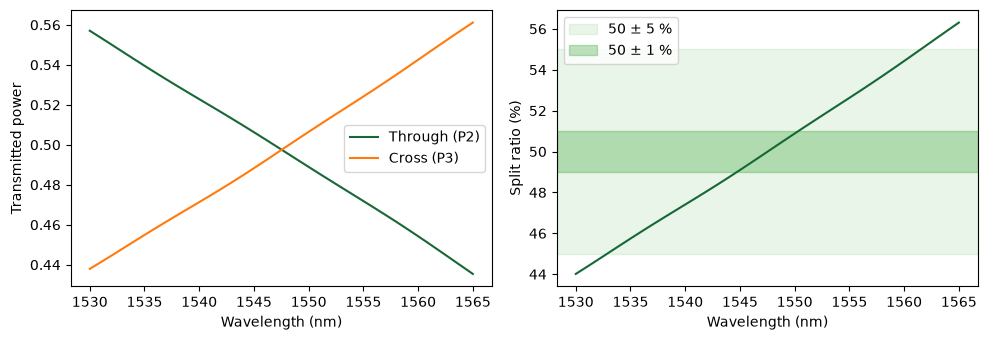

In [23]:
# Power in the through and cross ports for light entering P0
through = np.abs(s_coupler["P0@0", "P2@0"]) ** 2
cross = np.abs(s_coupler["P0@0", "P3@0"]) ** 2

# Split ratio: share of the output power in the cross port (%)
split = 100 * cross / (through + cross)

print(f"Through power at 1550 nm: {through[i_1550]:.4f}")
print(f"Cross power at 1550 nm: {cross[i_1550]:.4f}")
print(
    f"Excess loss at 1550 nm: {-10 * np.log10(through[i_1550] + cross[i_1550]):.3f} dB"
)
print(f"Split ratio at 1550 nm: {split[i_1550]:.2f} %")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5), tight_layout=True)

# Through and cross power across the band
ax[0].plot(wavelengths * 1e3, through, label="Through (P2)")
ax[0].plot(wavelengths * 1e3, cross, label="Cross (P3)")
ax[0].set_xlabel("Wavelength (nm)")
ax[0].set_ylabel("Transmitted power")
ax[0].legend()

# Split ratio across the band with the 50 ± 1 % and 50 ± 5 % windows
ax[1].plot(wavelengths * 1e3, split)
ax[1].axhspan(45, 55, color="tab:green", alpha=0.1, label="50 ± 5 %")
ax[1].axhspan(49, 51, color="tab:green", alpha=0.3, label="50 ± 1 %")
ax[1].set_xlabel("Wavelength (nm)")
ax[1].set_ylabel("Split ratio (%)")
ax[1].legend()
plt.show()

## Mach-Zehnder interferometer

The MZI places two copies of the coupler 150 µm apart and joins them with two arms. Both arms are drawn in a single call to [route_auto](https://docs.flexcompute.com/projects/photonforge/en/latest/_autosummary/photonforge.parametric.route_auto.html), PhotonForge's automatic router.

The arm length difference is stated as a target rather than drawn by hand. A [PathLengthMatching](https://docs.flexcompute.com/projects/photonforge/en/latest/_autosummary/photonforge.PathLengthMatching.html) group tells the router to equalize `offset + routed length` over the arms. Crediting the lower arm with an offset of $\Delta L$ therefore makes the router lengthen the upper arm by exactly $\Delta L$, which it does by inserting a meander of bends. The meander bends use the same 10 µm radius as the rest of the route.

The routed waveguides use waveguide models that take the effective index from a mode solve of the strip and the length from the layout. A [CircuitModel](https://docs.flexcompute.com/projects/photonforge/en/latest/_autosummary/photonforge.CircuitModel.html) then combines the scattering matrices of all parts, including the two copies of the FDTD coupler. The MZI therefore needs no new FDTD run.

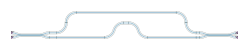

In [25]:
@pf.parametric_component
def mzi(
    *,
    gap: float = 0.2,
    coupling_length: float = 5.0,
    delta_length: float = 10.0,
    s_bend_length: float = 10.0,
    s_bend_offset: float = 2.0,
    arm_length: float = 150.0,
    arm_radius: float = 10.0,
):
    # Create the MZI component
    interferometer = pf.Component("MZI")

    # Coupler used for both the splitter and the combiner
    coupler = directional_coupler(
        gap=gap,
        coupling_length=coupling_length,
        s_bend_length=s_bend_length,
        s_bend_offset=s_bend_offset,
    )

    # Place the splitter at the origin and the combiner one arm length after it
    splitter = interferometer.add_reference(coupler)
    combiner = interferometer.add_reference(coupler)
    combiner.translate((splitter["P2"].center[0] + arm_length, 0))

    # Route both arms, making the upper arm longer than the lower one by delta_length
    arms = pf.parametric.route_auto(
        port1=[(splitter, "P2"), (splitter, "P3")],
        port2=[(combiner, "P0"), (combiner, "P1")],
        radius=arm_radius,
        matching=[pf.PathLengthMatching(offsets=[delta_length, 0.0])],
    )
    interferometer.add_reference(arms)

    # Expose the two inputs and two outputs and simulate the MZI as a circuit
    interferometer.add_port(
        [splitter["P0"], splitter["P1"], combiner["P2"], combiner["P3"]]
    )
    interferometer.add_model(pf.CircuitModel(), "Circuit")
    return interferometer


# Build the MZI for the current design parameters
device = mzi(
    gap=gap,
    coupling_length=coupling_length,
    delta_length=delta_length,
    s_bend_length=s_bend_length,
    s_bend_offset=s_bend_offset,
    arm_length=arm_length,
    arm_radius=arm_radius,
)
viewer(device)

The router reports nothing when it succeeds, so the next cell measures both arms with [route_length](https://docs.flexcompute.com/projects/photonforge/en/latest/_autosummary/photonforge.route_length.html) and prints the arm length difference it achieved. If a target cannot fit, the router leaves the arms unmatched, and this printout shows it.

In [27]:
# Routed arms inside the MZI, lower arm first
routes = next(
    ref.component for ref in device.references if ref.component.name != coupler.name
)

# Length of each routed arm (μm)
arm_lengths = [pf.route_length(ref.component) for ref in routes.references]

# Arm length difference achieved by the router (μm)
achieved_delta = arm_lengths[1] - arm_lengths[0]
print(f"Arm lengths: {arm_lengths[0]:.4f} μm (lower), {arm_lengths[1]:.4f} μm (upper)")
print(f"Arm length difference: {achieved_delta:.4f} μm (target {delta_length:.4f} μm)")

Arm lengths: 163.3889 μm (lower), 173.3892 μm (upper)
Arm length difference: 10.0003 μm (target 10.0000 μm)


The MZI ports follow the same convention as the coupler: `P0` and `P1` are the inputs on the left, and `P2` (bottom) and `P3` (top) are the outputs on the right. Light enters `P0`.

14:54:29 Eastern Standard Time Loading simulation from local cache. View cached 
                               task using web UI at                             
                               ]8;id=834987;https://tidy3d.simulation.cloud/workbench?taskId=mo-ba3b50e7-e19d-4ee4-a57a-de04e3934006\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=747263;https://tidy3d.simulation.cloud/workbench?taskId=mo-ba3b50e7-e19d-4ee4-a57a-de04e3934006\taskId]8;;\
                               ]8;id=834987;https://tidy3d.simulation.cloud/workbench?taskId=mo-ba3b50e7-e19d-4ee4-a57a-de04e3934006\=]8;;\]8;id=605254;https://tidy3d.simulation.cloud/workbench?taskId=mo-ba3b50e7-e19d-4ee4-a57a-de04e3934006\mo]8;;\]8;id=834987;https://tidy3d.simulation.cloud/workbench?taskId=mo-ba3b50e7-e19d-4ee4-a57a-de04e3934006\-ba3b50e7-e19d-4ee4-a57a-de04e3934006']8;;\.

14:54:30 Eastern Standard Time Loading simulation from local cache. View cached 
                               task using web UI at                             
                               ]8;id=951408;https://tidy3d.simulation.cloud/workbench?taskId=mo-f44d4258-64aa-4312-91c5-d32c52fa07a2\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=86387;https://tidy3d.simulation.cloud/workbench?taskId=mo-f44d4258-64aa-4312-91c5-d32c52fa07a2\taskId]8;;\
                               ]8;id=951408;https://tidy3d.simulation.cloud/workbench?taskId=mo-f44d4258-64aa-4312-91c5-d32c52fa07a2\=]8;;\]8;id=147176;https://tidy3d.simulation.cloud/workbench?taskId=mo-f44d4258-64aa-4312-91c5-d32c52fa07a2\mo]8;;\]8;id=951408;https://tidy3d.simulation.cloud/workbench?taskId=mo-f44d4258-64aa-4312-91c5-d32c52fa07a2\-f44d4258-64aa-4312-91c5-d32c52fa07a2']8;;\.

14:54:31 Eastern Standard Time Loading simulation from local cache. View cached 
                               task using web UI at                             
                               ]8;id=327248;https://tidy3d.simulation.cloud/workbench?taskId=mo-32ad32c3-39fc-48db-8f98-2b57d7cb36c1\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=875050;https://tidy3d.simulation.cloud/workbench?taskId=mo-32ad32c3-39fc-48db-8f98-2b57d7cb36c1\taskId]8;;\
                               ]8;id=327248;https://tidy3d.simulation.cloud/workbench?taskId=mo-32ad32c3-39fc-48db-8f98-2b57d7cb36c1\=]8;;\]8;id=837677;https://tidy3d.simulation.cloud/workbench?taskId=mo-32ad32c3-39fc-48db-8f98-2b57d7cb36c1\mo]8;;\]8;id=327248;https://tidy3d.simulation.cloud/workbench?taskId=mo-32ad32c3-39fc-48db-8f98-2b57d7cb36c1\-32ad32c3-39fc-48db-8f98-2b57d7cb36c1']8;;\.

                               Loading simulation from local cache. View cached 
                               task using web UI at                             
                               ]8;id=653997;https://tidy3d.simulation.cloud/workbench?taskId=mo-ae55b4fa-e3b1-4aec-a995-80906473ad11\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=917181;https://tidy3d.simulation.cloud/workbench?taskId=mo-ae55b4fa-e3b1-4aec-a995-80906473ad11\taskId]8;;\
                               ]8;id=653997;https://tidy3d.simulation.cloud/workbench?taskId=mo-ae55b4fa-e3b1-4aec-a995-80906473ad11\=]8;;\]8;id=305862;https://tidy3d.simulation.cloud/workbench?taskId=mo-ae55b4fa-e3b1-4aec-a995-80906473ad11\mo]8;;\]8;id=653997;https://tidy3d.simulation.cloud/workbench?taskId=mo-ae55b4fa-e3b1-4aec-a995-80906473ad11\-ae55b4fa-e3b1-4aec-a995-80906473ad11']8;;\.

                               Loading simulation from local cache. View cached 
                               task using web UI at                             
                               ]8;id=420994;https://tidy3d.simulation.cloud/workbench?taskId=mo-f98291a3-ada3-4a23-8c23-809d89ba8e95\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=55339;https://tidy3d.simulation.cloud/workbench?taskId=mo-f98291a3-ada3-4a23-8c23-809d89ba8e95\taskId]8;;\
                               ]8;id=420994;https://tidy3d.simulation.cloud/workbench?taskId=mo-f98291a3-ada3-4a23-8c23-809d89ba8e95\=]8;;\]8;id=962318;https://tidy3d.simulation.cloud/workbench?taskId=mo-f98291a3-ada3-4a23-8c23-809d89ba8e95\mo]8;;\]8;id=420994;https://tidy3d.simulation.cloud/workbench?taskId=mo-f98291a3-ada3-4a23-8c23-809d89ba8e95\-f98291a3-ada3-4a23-8c23-809d89ba8e95']8;;\.

14:54:32 Eastern Standard Time Loading simulation from local cache. View cached 
                               task using web UI at                             
                               ]8;id=198088;https://tidy3d.simulation.cloud/workbench?taskId=mo-7f8eaeb3-111c-4c00-8c01-b80b5a6fe45a\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=988586;https://tidy3d.simulation.cloud/workbench?taskId=mo-7f8eaeb3-111c-4c00-8c01-b80b5a6fe45a\taskId]8;;\
                               ]8;id=198088;https://tidy3d.simulation.cloud/workbench?taskId=mo-7f8eaeb3-111c-4c00-8c01-b80b5a6fe45a\=]8;;\]8;id=616555;https://tidy3d.simulation.cloud/workbench?taskId=mo-7f8eaeb3-111c-4c00-8c01-b80b5a6fe45a\mo]8;;\]8;id=198088;https://tidy3d.simulation.cloud/workbench?taskId=mo-7f8eaeb3-111c-4c00-8c01-b80b5a6fe45a\-7f8eaeb3-111c-4c00-8c01-b80b5a6fe45a']8;;\.

Arm phase difference at 1550 nm: 15.742 × 2π
Extinction ratio at 1550 nm: 0.4 dB


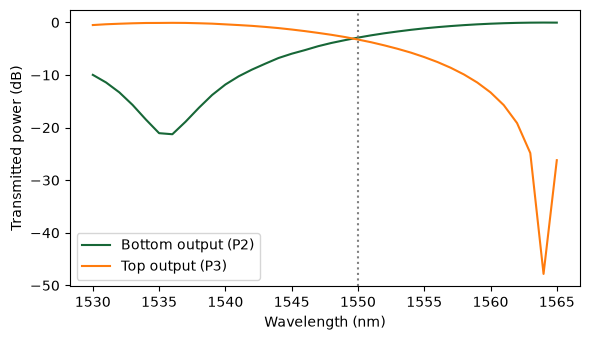

In [29]:
# Scattering matrix of the MZI from its parts
s_mzi = device.s_matrix(frequencies)

# Power in the two MZI outputs for light entering P0
p_bottom = np.abs(s_mzi["P0@0", "P2@0"]) ** 2
p_top = np.abs(s_mzi["P0@0", "P3@0"]) ** 2

# Extinction ratio at 1550 nm: bright output over dark output (dB)
bright = max(p_bottom[i_1550], p_top[i_1550])
dark = min(p_bottom[i_1550], p_top[i_1550])
extinction = 10 * np.log10(bright / dark)

# Phase difference between the arms at 1550 nm, in units of 2π
phase_cycles = n_eff * delta_length / 1.550
print(f"Arm phase difference at 1550 nm: {phase_cycles:.3f} × 2π")
print(f"Extinction ratio at 1550 nm: {extinction:.1f} dB")

fig, ax = plt.subplots(figsize=(6, 3.5), tight_layout=True)

# MZI outputs across the band in dB
ax.plot(wavelengths * 1e3, 10 * np.log10(p_bottom), label="Bottom output (P2)")
ax.plot(wavelengths * 1e3, 10 * np.log10(p_top), label="Top output (P3)")
ax.axvline(1550, color="gray", linestyle=":")
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Transmitted power (dB)")
ax.legend()
plt.show()

## Score

The score function checks the coupler and fabrication constraints. If all of them pass, the score is the MZI extinction ratio at 1550 nm in dB, capped at 40. A coupler that also stays within 50 ± 5 % across 1530 to 1565 nm earns a bonus of 5 points.

In [31]:
def mzi_score(split, min_feature, min_radius, extinction):
    # Pass or fail for every constraint of the challenge
    checks = {
        "Coupler split ratio at 1550 nm within 50 ± 1 %": abs(split[i_1550] - 50) <= 1,
        "Minimum gap or feature at least 100 nm": min_feature >= 0.1,
        "Minimum bend radius at least 5 μm": min_radius >= 5,
    }

    # Stretch goal: split ratio within 50 ± 5 % across the whole band
    stretch = bool(np.all(np.abs(split - 50) <= 5))

    # Print the outcome of each check
    for name, passed in checks.items():
        print(f"{'PASS' if passed else 'FAIL'}  {name}")
    print(
        f"{'PASS' if stretch else 'FAIL'}  Stretch: split ratio within 50 ± 5 % from 1530 to 1565 nm"
    )

    # Capped extinction ratio plus the stretch bonus if every constraint passes
    if not all(checks.values()):
        return 0.0
    return min(extinction, 40.0) + (5.0 if stretch else 0.0)


# Smallest drawn feature or gap and the tightest bend of the layout (μm)
min_feature = min(width, gap)
min_radius = min(s_bend_radius, arm_radius)

# Score of the current design
score = mzi_score(split, min_feature, min_radius, extinction)
print(f"\nScore: {score:.1f}")

PASS  Coupler split ratio at 1550 nm within 50 ± 1 %
PASS  Minimum gap or feature at least 100 nm
PASS  Minimum bend radius at least 5 μm
FAIL  Stretch: split ratio within 50 ± 5 % from 1530 to 1565 nm

Score: 0.4


## Where to go from here

- **Coupler first.** The split ratio is the only constraint the starting design fails. Use the coupling length estimate to get close before you run FDTD: the S-bends add coupling, so the straight section you need is shorter than $L_{50}$. Two or three FDTD runs at different coupling lengths are enough to interpolate to 50:50, since $P_{cross}$ follows $\sin^2$ of the total coupling.
- **Then the arms.** Choose $\Delta L$ so that the phase difference at 1550 nm is a whole number of $2\pi$ cycles, using $\Delta\varphi = 2\pi n_{eff} \Delta L / \lambda$ and the effective index printed above. Changing `delta_length` needs no new FDTD run, only the circuit calculation.
- **Stretch goal.** The split drifts across the band because $\Delta n / \lambda$ changes with wavelength. Compare that drift for different gaps and widths at their 50:50 coupling length; a coupler whose $\Delta n$ grows in step with $\lambda$ stays flat.
- **Budget.** Every new width, gap or coupling length costs one FDTD run. Print `cost` before running a sweep.

## Width-based broadband coupler
Symmetric coupler to phase control section (a wide top arm and a narrow bottom arm, joined with 1 µm tapers) and back to an identical symmetric coupler. The TMM needs n₊ and n₋ (coupler), n₁ and n₂ (arms), and θ_t1 and θ_t2 (tapers).

In [34]:
w_top = 0.55 # Width of the top (wide) arm in the phase control section (μm)
w_bottom = 0.40  # Width of the bottom (narrow) arm (μm)
L_t = 1.0 # Length of each taper (μm)

# Port specifications of the two arm waveguides
spec_top = pf.basic_technology(strip_width=w_top).ports["Strip"]
spec_bottom = pf.basic_technology(strip_width=w_bottom).ports["Strip"]

### Symmetric coupler

Progress: 100% 
Effective indices at 1550 nm: 2.4497 (even), 2.4320 (odd)


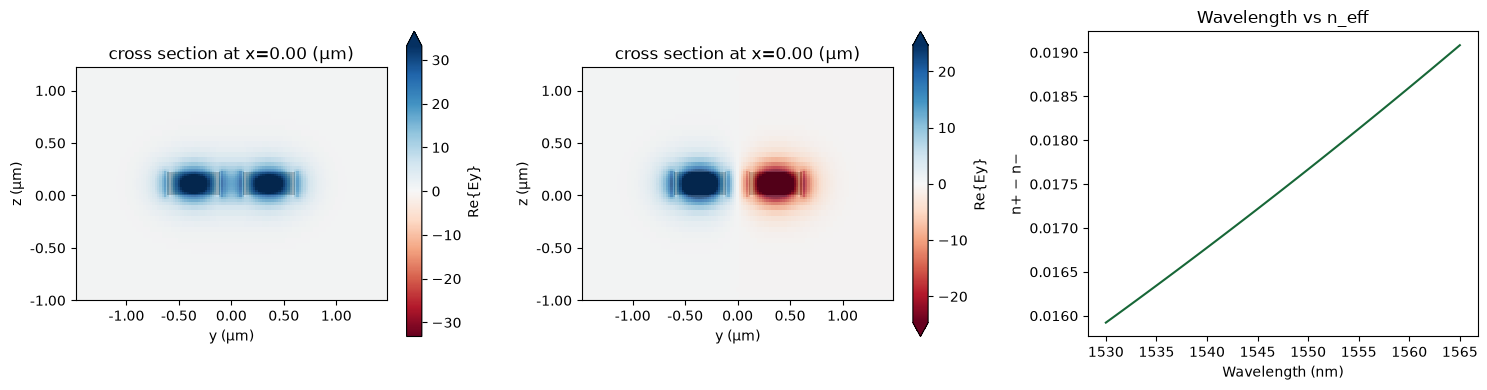

In [121]:
# Even (n+) and odd (n-) supermodes across the band, one mode solve
sc_modes = pf.port_modes(coupled_strips, frequencies)
n_p = sc_modes.data.n_eff.isel(mode_index=0).values
n_m = sc_modes.data.n_eff.isel(mode_index=1).values
del_n = n_p - n_m
print(f"Effective indices at 1550 nm: {n_p[i_1550]:.4f} (even), {n_m[i_1550]:.4f} (odd)")

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4), tight_layout=True)

sc_modes.plot_field("Ey", mode_index=0, f=frequencies[i_1550], ax=ax1)
sc_modes.plot_field("Ey", mode_index=1, f=frequencies[i_1550], ax=ax2)

ax3.plot(wavelengths * 1e3, del_n)
ax3.set_title("Wavelength vs n_eff")
ax3.set_xlabel("Wavelength (nm)")
ax3.set_ylabel("n+ − n−")

plt.show()


The S-bends also couple light. 

In [38]:
# Coupling angle added by the S-bends (rad)
theta_total = np.arcsin(np.sqrt(split / 100))
theta_bends = theta_total - np.pi * del_n * coupling_length / wavelengths

print(f"Coupling angle at 1550 nm: {theta_total[i_1550]:.3f} rad total, "
      f"{theta_bends[i_1550]:.3f} rad from the S-bends")

Coupling angle at 1550 nm: 0.794 rad total, 0.137 rad from the S-bends


### Phase control section
The phase control section changes the thickness of the waveguides in order to do phase compensation over the wavelength range.

Progress: 100% 
Progress: 100% 
Top arm (550 nm) at 1550 nm: n_eff 2.5086, n_g 4.1042
Bottom arm (400 nm) at 1550 nm: n_eff 2.2233, n_g 4.3718


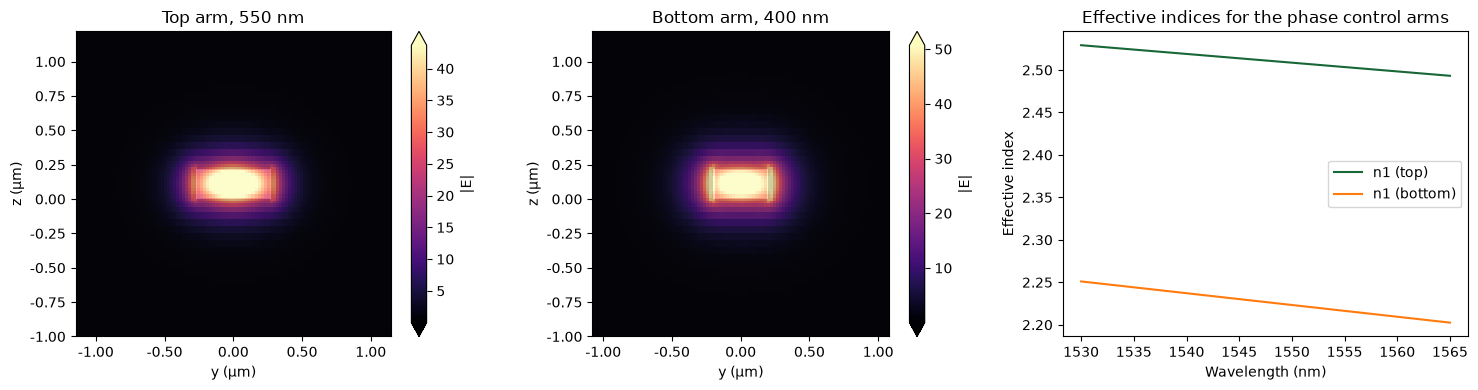

In [123]:
# Mode of the top (wide) and bottom (narrow) arm across the band
top_modes = pf.port_modes(spec_top, frequencies, group_index=True)
bottom_modes = pf.port_modes(spec_bottom, frequencies, group_index=True)

n_1 = top_modes.data.n_eff.isel(mode_index=0).values
n_2 = bottom_modes.data.n_eff.isel(mode_index=0).values

print(f"Top arm ({w_top * 1000:.0f} nm) at 1550 nm: n_eff {n_1[i_1550]:.4f}, "
      f"n_g {top_modes.data.n_group.isel(mode_index=0).values[i_1550]:.4f}")
print(f"Bottom arm ({w_bottom * 1000:.0f} nm) at 1550 nm: n_eff {n_2[i_1550]:.4f}, "
      f"n_g {bottom_modes.data.n_group.isel(mode_index=0).values[i_1550]:.4f}")

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4), tight_layout=True)

top_modes.plot_field("E", "abs", mode_index=0, f=frequencies[i_1550], ax=ax1)
ax1.set_title(f"Top arm, {w_top * 1000:.0f} nm")

bottom_modes.plot_field("E", "abs", mode_index=0, f=frequencies[i_1550], ax=ax2)
ax2.set_title(f"Bottom arm, {w_bottom * 1000:.0f} nm")

ax3.plot(wavelengths * 1e3, n_1, label="n1 (top)")
ax3.plot(wavelengths * 1e3, n_2, label="n1 (bottom)")
ax3.set_title("Effective indices for the phase control arms")
ax3.set_xlabel("Wavelength (nm)")
ax3.set_ylabel("Effective index")
ax3.legend()

plt.show()

### Tapers

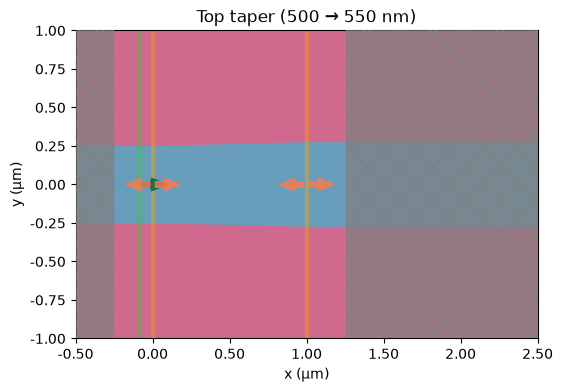

Top taper cost: 0.0


In [80]:
# Top taper: 500 nm to 550 nm over L_t, simulated with FDTD
taper_top = pf.parametric.transition(port_spec1="Strip", port_spec2=spec_top, length=L_t,
                                     model=pf.Tidy3DModel(grid_spec=12))

sim_top = taper_top.active_model.get_simulations(taper_top, frequencies)["P0@0"]

# Zoom in on the taper; without hlim/vlim the absorbing layers fill the plot
fig, ax = plt.subplots(figsize=(8, 4))
sim_top.plot(z=0.11, ax=ax, hlim=(-0.5, 2.5), vlim=(-1, 1))
ax.set_title("Top taper (500 → 550 nm)")
plt.show()

print("Top taper cost:", taper_top.active_model.estimate_cost(taper_top, frequencies))

14:55:11 Eastern Standard Time Loading simulation from local cache. View cached 
                               task using web UI at                             
                               ]8;id=236450;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2d6e9573-aae9-4aaa-b58f-cd0a1eea181b\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=422262;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2d6e9573-aae9-4aaa-b58f-cd0a1eea181b\taskId]8;;\
                               ]8;id=236450;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2d6e9573-aae9-4aaa-b58f-cd0a1eea181b\=]8;;\]8;id=814409;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2d6e9573-aae9-4aaa-b58f-cd0a1eea181b\fdve]8;;\]8;id=236450;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2d6e9573-aae9-4aaa-b58f-cd0a1eea181b\-2d6e9573-aae9-4aaa-b58f-cd0a1eea181b']8;;\.

                               Loading simulation from local cache. View cached 
                               task using web UI at                             
                               ]8;id=236616;https://tidy3d.simulation.cloud/workbench?taskId=fdve-a6c5adea-c6be-4114-95e9-44a93bb935ea\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=312439;https://tidy3d.simulation.cloud/workbench?taskId=fdve-a6c5adea-c6be-4114-95e9-44a93bb935ea\taskId]8;;\
                               ]8;id=236616;https://tidy3d.simulation.cloud/workbench?taskId=fdve-a6c5adea-c6be-4114-95e9-44a93bb935ea\=]8;;\]8;id=456065;https://tidy3d.simulation.cloud/workbench?taskId=fdve-a6c5adea-c6be-4114-95e9-44a93bb935ea\fdve]8;;\]8;id=236616;https://tidy3d.simulation.cloud/workbench?taskId=fdve-a6c5adea-c6be-4114-95e9-44a93bb935ea\-a6c5adea-c6be-4114-95e9-44a93bb935ea']8;;\.

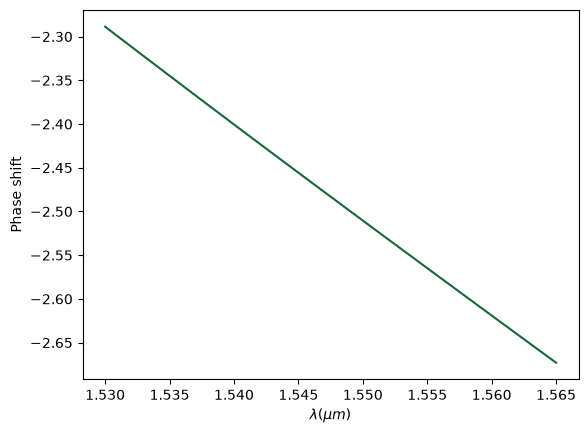

In [43]:
# Run the FDTD and take the phase from the start to the end of the taper
s_top = taper_top.s_matrix(frequencies)
theta_t1 = np.angle(s_top["P0@0", "P1@0"])

plt.plot(wavelengths, np.unwrap(theta_t1))
plt.xlabel(r"$\lambda (\mu m)$")
plt.ylabel("Phase shift")
plt.show()

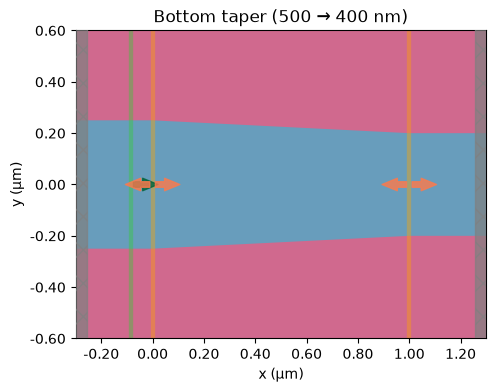

14:55:13 Eastern Standard Time Loading simulation from local cache. View cached 
                               task using web UI at                             
                               ]8;id=640989;https://tidy3d.simulation.cloud/workbench?taskId=fdve-39815ad9-3921-4b7e-931c-360ca78b4680\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=703170;https://tidy3d.simulation.cloud/workbench?taskId=fdve-39815ad9-3921-4b7e-931c-360ca78b4680\taskId]8;;\
                               ]8;id=640989;https://tidy3d.simulation.cloud/workbench?taskId=fdve-39815ad9-3921-4b7e-931c-360ca78b4680\=]8;;\]8;id=986282;https://tidy3d.simulation.cloud/workbench?taskId=fdve-39815ad9-3921-4b7e-931c-360ca78b4680\fdve]8;;\]8;id=640989;https://tidy3d.simulation.cloud/workbench?taskId=fdve-39815ad9-3921-4b7e-931c-360ca78b4680\-39815ad9-3921-4b7e-931c-360ca78b4680']8;;\.

                               Loading simulation from local cache. View cached 
                               task using web UI at                             
                               ]8;id=110566;https://tidy3d.simulation.cloud/workbench?taskId=fdve-0f868f32-bbd7-4f00-8488-d461fb456343\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=657625;https://tidy3d.simulation.cloud/workbench?taskId=fdve-0f868f32-bbd7-4f00-8488-d461fb456343\taskId]8;;\
                               ]8;id=110566;https://tidy3d.simulation.cloud/workbench?taskId=fdve-0f868f32-bbd7-4f00-8488-d461fb456343\=]8;;\]8;id=558274;https://tidy3d.simulation.cloud/workbench?taskId=fdve-0f868f32-bbd7-4f00-8488-d461fb456343\fdve]8;;\]8;id=110566;https://tidy3d.simulation.cloud/workbench?taskId=fdve-0f868f32-bbd7-4f00-8488-d461fb456343\-0f868f32-bbd7-4f00-8488-d461fb456343']8;;\.

Bottom taper cost: 0.0


In [44]:
# Bottom taper: 500 nm to 400 nm over L_t
taper_bottom = pf.parametric.transition(port_spec1="Strip", port_spec2=spec_bottom, length=L_t,
                                        model=pf.Tidy3DModel(grid_spec=12))
sim_bottom = taper_bottom.active_model.get_simulations(taper_bottom, frequencies)["P0@0"]

fig, ax = plt.subplots(figsize=(6, 4))
sim_bottom.plot(z=0.11, ax=ax, hlim=(-0.3, 1.3), vlim=(-0.6, 0.6))
ax.set_title("Bottom taper (500 → 400 nm)")
plt.show()

print("Bottom taper cost:", taper_bottom.active_model.estimate_cost(taper_bottom, frequencies))

14:55:14 Eastern Standard Time Loading simulation from local cache. View cached 
                               task using web UI at                             
                               ]8;id=554525;https://tidy3d.simulation.cloud/workbench?taskId=fdve-39815ad9-3921-4b7e-931c-360ca78b4680\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=395750;https://tidy3d.simulation.cloud/workbench?taskId=fdve-39815ad9-3921-4b7e-931c-360ca78b4680\taskId]8;;\
                               ]8;id=554525;https://tidy3d.simulation.cloud/workbench?taskId=fdve-39815ad9-3921-4b7e-931c-360ca78b4680\=]8;;\]8;id=957132;https://tidy3d.simulation.cloud/workbench?taskId=fdve-39815ad9-3921-4b7e-931c-360ca78b4680\fdve]8;;\]8;id=554525;https://tidy3d.simulation.cloud/workbench?taskId=fdve-39815ad9-3921-4b7e-931c-360ca78b4680\-39815ad9-3921-4b7e-931c-360ca78b4680']8;;\.

                               Loading simulation from local cache. View cached 
                               task using web UI at                             
                               ]8;id=923316;https://tidy3d.simulation.cloud/workbench?taskId=fdve-0f868f32-bbd7-4f00-8488-d461fb456343\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=974900;https://tidy3d.simulation.cloud/workbench?taskId=fdve-0f868f32-bbd7-4f00-8488-d461fb456343\taskId]8;;\
                               ]8;id=923316;https://tidy3d.simulation.cloud/workbench?taskId=fdve-0f868f32-bbd7-4f00-8488-d461fb456343\=]8;;\]8;id=134906;https://tidy3d.simulation.cloud/workbench?taskId=fdve-0f868f32-bbd7-4f00-8488-d461fb456343\fdve]8;;\]8;id=923316;https://tidy3d.simulation.cloud/workbench?taskId=fdve-0f868f32-bbd7-4f00-8488-d461fb456343\-0f868f32-bbd7-4f00-8488-d461fb456343']8;;\.

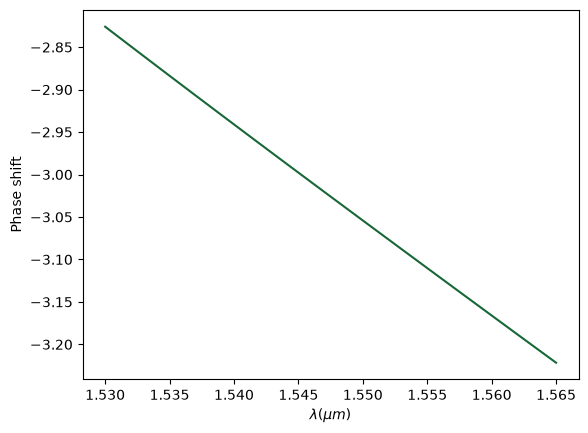

θ_t1 − θ_t2 at 1550 nm: 0.544 rad


In [45]:
s_bottom = taper_bottom.s_matrix(frequencies)
theta_t2 = np.angle(s_bottom["P0@0", "P1@0"])

plt.plot(wavelengths, np.unwrap(theta_t2))
plt.xlabel(r"$\lambda (\mu m)$")
plt.ylabel("Phase shift")
plt.show()

# Difference between the two tapers at 1550 nm, wrapped to -pi to pi
print(f"θ_t1 − θ_t2 at 1550 nm: {np.angle(np.exp(1j * (theta_t1 - theta_t2)))[i_1550]:.3f} rad")

Taper phase difference at 1550 nm: 0.544 rad


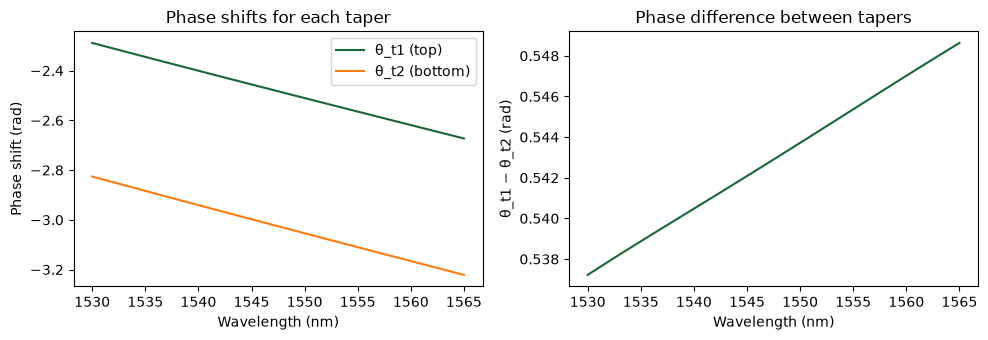

In [126]:
# Transmission phase of each taper (P0 to P1)
s_top = taper_top.s_matrix(frequencies)
s_bottom = taper_bottom.s_matrix(frequencies)
theta_t1 = np.unwrap(np.angle(s_top["P0@0", "P1@0"]))
theta_t2 = np.unwrap(np.angle(s_bottom["P0@0", "P1@0"]))

# Phase difference between the tapers, wrapped to -pi to pi
taper_diff = np.angle(np.exp(1j * (theta_t1 - theta_t2)))
print(f"Taper phase difference at 1550 nm: {taper_diff[i_1550]:.3f} rad")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5), tight_layout=True)
ax[0].plot(wavelengths * 1e3, theta_t1, label="θ_t1 (top)")
ax[0].plot(wavelengths * 1e3, theta_t2, label="θ_t2 (bottom)")
ax[0].set_ylabel("Phase shift (rad)")
ax[0].set_title("Phase shifts for each taper")
ax[0].legend()
ax[1].plot(wavelengths * 1e3, taper_diff)
ax[1].set_ylabel("θ_t1 − θ_t2 (rad)")
ax[1].set_title("Phase difference between tapers")
for a in ax:
    a.set_xlabel("Wavelength (nm)")
plt.show()

What we see above is very good. This phase difference will compensate for the difference in effective index over the wavelength.

In [103]:
from scipy.io import savemat

# Save TMM inputs to matlab file
savemat("tmm_inputs.mat", dict(wavelengths=wavelengths, n_p=n_p, n_m=n_m, theta_bends=theta_bends,
                               n_1=n_1, n_2=n_2, theta_t1=theta_t1, theta_t2=theta_t2))

In [105]:
def bb_coupler(L_1, L_2):
    bb = pf.Component("BROADBAND_COUPLER")
    dc = directional_coupler(gap=gap, coupling_length=L_1,
                             s_bend_length=s_bend_length, s_bend_offset=s_bend_offset)
    first = bb.add_reference(dc)

    # Top arm: taper out, straight, taper back (turned around)
    top_in = bb.add_reference(taper_top)
    top_in.connect("P0", first["P3"])
    top_wg = bb.add_reference(pf.parametric.straight(port_spec=spec_top, length=L_2))
    top_wg.connect("P0", top_in["P1"])
    top_out = bb.add_reference(taper_top)
    top_out.connect("P1", top_wg["P1"])

    # Bottom arm, the same with the narrow taper
    bottom_in = bb.add_reference(taper_bottom)
    bottom_in.connect("P0", first["P2"])
    bottom_wg = bb.add_reference(pf.parametric.straight(port_spec=spec_bottom, length=L_2))
    bottom_wg.connect("P0", bottom_in["P1"])
    bottom_out = bb.add_reference(taper_bottom)
    bottom_out.connect("P1", bottom_wg["P1"])

    # Second coupler, identical to the first
    second = bb.add_reference(dc)
    second.connect("P0", bottom_out["P0"])

    bb.add_port([first["P0"], first["P1"], second["P2"], second["P3"]])
    bb.add_model(pf.CircuitModel(), "Circuit")
    return bb


def bb_split(L_1, L_2):
    # Split ratio
    s = bb_coupler(L_1, L_2).s_matrix(frequencies)
    through_bb = np.abs(s["P0@0", "P2@0"]) ** 2
    cross_bb = np.abs(s["P0@0", "P3@0"]) ** 2
    return 100 * cross_bb / (through_bb + cross_bb)


L_1 = 13.4   
L_2 = 5.74  
viewer(bb_coupler(L_1, L_2))

In [107]:
# Scan L_2 around the TMM value 
print("  L_2 (μm)   split at 1550 (%)   worst over C-band (%)")
for L_2_try in np.arange(L_2 - 0.5, L_2 + 0.5, 0.05):
    sp = bb_split(L_1, L_2_try)
    print(f"  {L_2_try:6.2f}       {sp[i_1550]:6.2f}            {np.max(np.abs(sp - 50)):6.2f}")

  L_2 (μm)   split at 1550 (%)   worst over C-band (%)
Uploading task 'P0@0…'
Starting task 'P0@0': https://tidy3d.simulation.cloud/workbench?taskId=fdve-f2e179e8-db1c-4be4-8d0a-4112885721c2
    5.24        72.11             23.83
    5.29        70.15             21.63
    5.34        68.05             19.33
    5.39        65.85             16.94
    5.44        63.60             14.48
    5.49        61.33             11.97
    5.54        59.03              9.44
    5.59        56.66              6.88
    5.64        54.23              4.41
    5.69        51.74              1.94
    5.74        49.21              1.36
    5.79        46.68              3.88
    5.84        44.16              6.58
    5.89        41.65              9.25
    5.94        39.16             11.90
    5.99        36.67             14.53
    6.04        34.18             17.13
    6.09        31.71             19.70
    6.14        29.28             22.21
    6.19        26.92             24.64


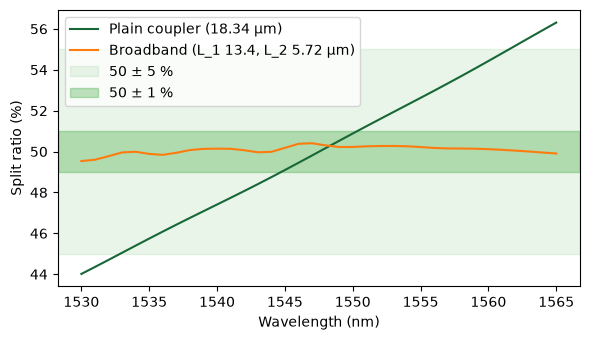

In [115]:
L_2 = 5.72 # in the middle of best row from scan above
split_bb = bb_split(L_1, L_2)

fig, ax = plt.subplots(figsize=(6, 3.5), tight_layout=True)
ax.plot(wavelengths * 1e3, split, label=f"Plain coupler ({coupling_length} μm)")
ax.plot(wavelengths * 1e3, split_bb, label=f"Broadband (L_1 {L_1}, L_2 {L_2} μm)")
ax.axhspan(45, 55, color="tab:green", alpha=0.1, label="50 ± 5 %")
ax.axhspan(49, 51, color="tab:green", alpha=0.3, label="50 ± 1 %")
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Split ratio (%)")
ax.legend()
plt.show()

In [117]:
# AI-gen MZI + scoring for now
def mzi_bb(coupler_bb, delta_length):
    # Same as the starter MZI, with the broadband coupler as splitter and combiner
    interferometer = pf.Component("MZI_BB")
    
    splitter = interferometer.add_reference(coupler_bb)
    combiner = interferometer.add_reference(coupler_bb)
    combiner.translate((splitter["P2"].center[0] + arm_length, 0))
    
    arms = pf.parametric.route_auto(
        port1=[(splitter, "P2"), (splitter, "P3")], port2=[(combiner, "P0"), (combiner, "P1")],
        radius=arm_radius, matching=[pf.PathLengthMatching(offsets=[delta_length, 0.0])])
    
    interferometer.add_reference(arms)
    interferometer.add_port([splitter["P0"], splitter["P1"], combiner["P2"], combiner["P3"]])
    interferometer.add_model(pf.CircuitModel(), "Circuit")
    
    return interferometer


def extinction_bb(delta_length):
    # Extinction ratio at 1550 nm (dB)
    s = mzi_bb(bb_coupler(L_1, L_2), delta_length).s_matrix(frequencies)
    
    p_bottom = np.abs(s["P0@0", "P2@0"][i_1550]) ** 2
    p_top = np.abs(s["P0@0", "P3@0"][i_1550]) ** 2
    
    return 10 * np.log10(max(p_bottom, p_top) / min(p_bottom, p_top))


# The broadband coupler adds its own phase, so search for the best deltaL
start = round(n_eff * 10.0 / 1.550) * 1.550 / n_eff
coarse = np.arange(start - 0.35, start + 0.35, 0.01)
best = coarse[np.argmax([extinction_bb(d) for d in coarse])]
fine = np.arange(best - 0.01, best + 0.01, 0.0005)
fine_er = [extinction_bb(d) for d in fine]
delta_length_bb = fine[np.argmax(fine_er)]
extinction_best = max(fine_er)
print(f"Best ΔL: {delta_length_bb:.4f} μm, extinction ratio {extinction_best:.1f} dB")

viewer(mzi_bb(bb_coupler(L_1, L_2), delta_length_bb))
score_bb = mzi_score(split_bb, min(width, gap, w_bottom), min_radius, extinction_best)
print(f"\nBroadband score: {score_bb:.1f}")

Best ΔL: 10.2422 μm, extinction ratio 46.8 dB
PASS  Coupler split ratio at 1550 nm within 50 ± 1 %
PASS  Minimum gap or feature at least 100 nm
PASS  Minimum bend radius at least 5 μm
PASS  Stretch: split ratio within 50 ± 5 % from 1530 to 1565 nm

Broadband score: 45.0
